# 00 · Ejemplo completo: de la configuración a las comprobaciones

**Objetivo:** recorrer una vez todo el flujo de gwsim, con un ejemplo que puedes copiar y en el que solo tienes que cambiar parámetros:

```
configuración JSON  →  python -m gwsim generate  →  fichero HDF5  →  gwsim.load / h5py  →  tu análisis
```

Es la versión notebook de `examples/full_pipeline_example/`: el mismo contenido, con cada paso explicado. Al terminar sabrás escribir una configuración, validarla, generar, saber qué hay en el fichero, leerlo y comprobar que los datos tienen sentido.

**Requisitos:** el entorno de gwsim como kernel de este notebook (guía, paso 3). El paquete de PSD `psd_pack_o3b.npz` en la raíz del repositorio es recomendable (guía, paso 5); si no está, el notebook usa ruido analítico y lo avisa.

**Tiempo aproximado:** 1–3 minutos en CPU (20 señales).

## 1. Comprobar el entorno y el paquete de PSD

Esta celda:

- localiza la raíz del repositorio (el notebook está en `tutorials/`) y la añade a `sys.path`, para importar `gwsim` sin instalarlo;
- imprime las versiones (deben ser las de `environment.yml`);
- busca el paquete de PSD. `PSD_PACK` es su ruta; si es relativa, se interpreta respecto a la raíz del repositorio.

Si aparece un aviso sobre `pkg_resources`, es inofensivo.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import gwsim, pycbc, lal, h5py
print('gwsim', gwsim.__version__, '| pycbc', pycbc.__version__, '| lalsuite', lal.__version__,
      '| numpy', np.__version__, '| h5py', h5py.__version__)

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')
print('Paquete de PSD:', pack_path if USE_PACK else 'no encontrado -> ruido analítico')

OUT = ROOT / 'tutorials' / 'salidas' / '00_full_pipeline_example'
OUT.mkdir(parents=True, exist_ok=True)
COLORS = {'H1': '#d55e00', 'L1': '#0072b2', 'V1': '#009e73'}   # paleta Okabe-Ito
IFOS = ('H1', 'L1', 'V1')

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


gwsim 0.1.0 | pycbc 2.9.0 | lalsuite 7.7.1 | numpy 2.2.6 | h5py 3.16.0
Paquete de PSD: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/psd_pack_o3b.npz


## 2. Escribir la configuración

Una configuración de gwsim es un JSON, que en Python es un `dict`. La escribimos aquí y la guardamos en un fichero, que es lo que lee `python -m gwsim generate`. Las claves que no escribas toman su valor por defecto (`docs/CONFIGURACION.md`).

| Clave | Valor | Qué significa |
|---|---|---|
| `n_samples` | 20 | Número de señales. |
| `seed` | 20261123 | Semilla global: con la misma semilla y la misma configuración sale exactamente el mismo fichero. |
| `mode` | `snr` | La distancia se ajusta para que cada señal tenga su SNR de red objetivo. |
| `outputs` | `X`, `X_noise` | `X` = señal + ruido procesados; `X_noise` = **la misma** realización de ruido, sin señal. |
| `click_free` | `true` | Señal sin el clic artificial del arranque a 30 Hz (`docs/FISICA.md` §6). |
| `noise` | paquete, split `train` | Ruido gaussiano con las PSD de O3b de los entornos `train` (o analítico, si no hay paquete). |
| `prior.masses` | uniformes en [20, 60] M☉ | m₁ y m₂ independientes, después ordenadas (m₁ ≥ m₂). |
| `prior.spin_1z`, `spin_2z` | uniformes en [−0,5; 0,5] | Espines alineados con el momento angular orbital. |
| `prior.inclination`, `dec` | isótropos | cos ι y sen δ uniformes: orientaciones y posiciones repartidas por igual sobre la esfera. |
| `prior.ra`, `polarization_angle` | uniformes | En [0, 2π). |
| `prior.target_network_snr` | uniforme en [10, 25) | SNR de red objetivo. |

In [2]:
noise_cfg = ({'source': 'psd_pack', 'psd_pack': str(pack_path), 'splits': ['train']} if USE_PACK
             else {'source': 'analytic', 'gps_range': [1256655618.0, 1269363618.0]})
config = {
    'description': 'Ejemplo completo: 20 señales, masas 20-60, espines U[-0.5, 0.5], SNR U[10, 25), pares X / X_noise',
    'n_samples': 20,
    'seed': 20261123,
    'mode': 'snr',
    'outputs': ['X', 'X_noise'],
    'click_free': True,
    'noise': noise_cfg,
    'prior': {
        'masses': {'distribution': 'components_uniform', 'range': [20.0, 60.0]},
        'spin_1z': {'distribution': 'uniform', 'range': [-0.5, 0.5]},
        'spin_2z': {'distribution': 'uniform', 'range': [-0.5, 0.5]},
        'inclination': {'distribution': 'isotropic'},
        'ra': {'distribution': 'uniform'},
        'dec': {'distribution': 'isotropic'},
        'polarization_angle': {'distribution': 'uniform'},
        'target_network_snr': {'distribution': 'uniform', 'range': [10.0, 25.0]},
    },
}
config_path = OUT / 'config.json'
config_path.write_text(json.dumps(config, indent=2))
print('Configuración guardada en', config_path)

Configuración guardada en /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_full_pipeline_example/config.json


## 3. Validar la configuración

`load_config` hace la misma validación que `generate`, sin escribir nada: aplica los valores por defecto, resuelve las rutas y comprueba cada clave.

- Si algo está mal (una clave mal escrita, un rango al revés…), lanza `ConfigError` con un mensaje que dice qué falla.
- Si es válida pero sale de la región validada, devuelve **avisos** (`docs/VALIDEZ.md`).

Con esta configuración no debe haber avisos.

In [3]:
from gwsim.config import load_config, ConfigError
try:
    cfg_full, avisos = load_config(config_path)
    print('Configuración válida:', cfg_full['n_samples'], 'señales, modo', cfg_full['mode'], ', salidas', cfg_full['outputs'])
    for a in avisos:
        print('AVISO:', a)
    size = gwsim.estimate_size(config, config['n_samples'])
    print(f'Tamaño previsto del fichero (sin comprimir): {size / 2**20:.1f} MiB')
except ConfigError as exc:
    print('Configuración NO válida:', exc)

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Configuración válida: 20 señales, modo snr , salidas ['X', 'X_noise']
Tamaño previsto del fichero (sin comprimir): 7.5 MiB


## 4. Generar

Lanzamos la misma orden que usarías en la terminal, `python -m gwsim generate`, con `subprocess.run`. `sys.executable` es el Python de este kernel, así que se usa el mismo entorno.

- `--output` es el fichero que se crea.
- gwsim **nunca sobrescribe**, así que primero borramos la salida de una ejecución anterior de este notebook.
- Para conjuntos grandes, añade `--workers N` (tutorial 06).

In [4]:
h5_path = OUT / 'ejemplo.h5'
if h5_path.exists():
    h5_path.unlink()
cmd = [sys.executable, '-m', 'gwsim', 'generate', '--config', str(config_path), '--output', str(h5_path)]
result = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(f'gwsim generate terminó con código {result.returncode}')

Creado /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_full_pipeline_example/ejemplo.h5: 20 filas
20 filas pendientes de 20; 1 proceso(s)
1/20 (hechas 1, fallidas 0); 14 s
2/20 (hechas 2, fallidas 0); 16 s
4/20 (hechas 4, fallidas 0); 17 s
5/20 (hechas 5, fallidas 0); 18 s
6/20 (hechas 6, fallidas 0); 20 s
7/20 (hechas 7, fallidas 0); 23 s
8/20 (hechas 8, fallidas 0); 24 s
9/20 (hechas 9, fallidas 0); 25 s
10/20 (hechas 10, fallidas 0); 26 s
11/20 (hechas 11, fallidas 0); 27 s
12/20 (hechas 12, fallidas 0); 27 s
13/20 (hechas 13, fallidas 0); 28 s
14/20 (hechas 14, fallidas 0); 29 s
16/20 (hechas 16, fallidas 0); 31 s
17/20 (hechas 17, fallidas 0); 32 s
18/20 (hechas 18, fallidas 0); 33 s
19/20 (hechas 19, fallidas 0); 34 s
20/20 (hechas 20, fallidas 0); 35 s
Terminado: /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_full_pipeline_example/ejemplo.h5 (hechas 20, fallidas 0)



## 5. Qué hay dentro del fichero

Un HDF5 contiene arrays con nombre (*datasets*) y atributos. El de gwsim tiene:

- un array `(n, 3, 16384)` por salida pedida (`X`, `X_noise`);
- `status` (0 pendiente, 1 hecha, 2 fallida) y `error` (el motivo, si falló);
- `y` = `[chirp_mass, total_mass, chi_eff]`;
- los metadatos de cada señal (parámetros, SNR, distancia, tiempos, ruido, semillas);
- como atributo `config_json`, **la configuración completa** con la que se generó.

Recorremos el árbol y recuperamos la configuración como JSON. Ese fichero se puede pasar tal cual a `generate --config` para repetir la generación o variarla. Desde la terminal, `h5ls -r ejemplo.h5` muestra lo mismo.

In [5]:
with h5py.File(h5_path, 'r') as h:
    h.visititems(lambda name, obj: print(f'{name:<26} {str(obj.shape):<18} {obj.dtype}')
                 if isinstance(obj, h5py.Dataset) else None)
    print('\nAtributos:', {k: v for k, v in h.attrs.items() if k not in ('config_json', 'warnings')})
    cfg_saved = json.loads(h.attrs['config_json'])
recovered = OUT / 'config_recuperada.json'
recovered.write_text(json.dumps(cfg_saved, indent=2))
print('Configuración recuperada en', recovered, '-> seed', cfg_saved['seed'], '| splits', cfg_saved['noise'].get('splits'))

X                          (20, 3, 16384)     float32
X_noise                    (20, 3, 16384)     float32
actual_geocentric_time     (20,)              float64
align_residual_rad         (20,)              float64
band_f_lower               (20,)              float64
band_taper_end_hz          (20,)              float64
block_id                   (20,)              object
chi_eff                    (20,)              float64
chirp_mass                 (20,)              float64
dec                        (20,)              float64
distance_input             (20,)              float64
edge_samples_H1            (20,)              int64
edge_samples_L1            (20,)              int64
edge_samples_V1            (20,)              int64
error                      (20,)              object
final_distance             (20,)              float64
final_network_snr          (20,)              float64
full_network_duration      (20,)              float64
gaussian_seed              (20,)    

## 6. Cargar con `gwsim.load`

`gwsim.load` devuelve un dict con las salidas pedidas y todos los metadatos, solo de las filas hechas (`status == 1`). Con `only_ok=False` y `outputs=()` se obtienen los metadatos de **todas** las filas, incluidas las fallidas, sin cargar los arrays grandes.

Para ficheros que no caben en memoria, lee por bloques con h5py (tutorial 06).

In [6]:
everything = gwsim.load(h5_path, outputs=(), only_ok=False)
d = gwsim.load(h5_path, outputs=('X', 'X_noise'))
status, errors = everything['status'], everything['error']
n_ok, n_fail = int((status == 1).sum()), int((status == 2).sum())
print(f'filas: {len(status)} -> hechas {n_ok}, fallidas {n_fail}')
for i in np.flatnonzero(status == 2):
    print(f'  fila {i} fallida: {errors[i]}')
print('X:', d['X'].shape, d['X'].dtype, '| X_noise:', d['X_noise'].shape, '| y:', d['y'].shape)
for name, label in (('total_mass', 'M_tot [M☉]'), ('chi_eff', 'χ_eff'), ('final_network_snr', 'SNR final')):
    print(f'{label:<11} mín {d[name].min():8.3f}   máx {d[name].max():8.3f}')

filas: 20 -> hechas 20, fallidas 0
X: (20, 3, 16384) float32 | X_noise: (20, 3, 16384) | y: (20, 3)
M_tot [M☉]  mín   45.110   máx  108.435
χ_eff       mín   -0.332   máx    0.403
SNR final   mín   10.565   máx   23.961


## 7. Comprobaciones

Antes de usar unos datos, comprueba que son lo que crees. Cada comprobación da **OK** o **FALLO**:

1. **Hay filas hechas.**
2. **Forma (3, 16384)**: 3 detectores × 4 s a 4096 Hz.
3. **Valores finitos**: ni NaN ni infinitos.
4. **Media ≈ 0 y desviación ≈ 1 por canal en X**: es lo que garantiza el z-score, (x − media)/(desviación + 10⁻⁶).
5. **|SNR final − objetivo| / objetivo ≤ 0,05**: la tolerancia del reescalado de la distancia.
6. **Parámetros dentro del prior**: masas en [20, 60], espines en [−0,5; 0,5], SNR en [10, 25] y ángulos en sus rangos naturales.

In [7]:
import math
checks = []
def check(name, ok, detail=''):
    checks.append(bool(ok))
    print(f"[{'OK' if ok else 'FALLO':>5}] {name}" + (f': {detail}' if detail else ''))

check('hay filas hechas', n_ok > 0, f'{n_ok} de {len(status)}')
X, Xn = d['X'].astype(np.float64), d['X_noise'].astype(np.float64)
check('forma (3, 16384) por señal', X.shape[1:] == (3, 16384) and Xn.shape[1:] == (3, 16384), f'X {X.shape}, X_noise {Xn.shape}')
check('valores finitos', np.isfinite(X).all() and np.isfinite(Xn).all())
mean_err, std_err = float(np.abs(X.mean(axis=2)).max()), float(np.abs(X.std(axis=2) - 1).max())
check('media ≈ 0 por canal en X', mean_err < 1e-3, f'máx |media| = {mean_err:.2e}')
check('desviación ≈ 1 por canal en X', std_err < 1e-3, f'máx |desv − 1| = {std_err:.2e}')
rel = np.abs(d['final_network_snr'] - d['target_network_snr']) / d['target_network_snr']
check('|SNR final − objetivo| / objetivo ≤ 0.05', rel.max() <= 0.05, f'máx {rel.max():.2e}')
limits = {'mass_1': (20, 60), 'mass_2': (20, 60), 'spin_1z': (-0.5, 0.5), 'spin_2z': (-0.5, 0.5),
          'target_network_snr': (10, 25), 'inclination': (0, math.pi), 'dec': (-math.pi / 2, math.pi / 2),
          'ra': (0, 2 * math.pi), 'polarization_angle': (0, 2 * math.pi)}
bad = [f'{k} fuera de [{lo:g}, {hi:g}]' for k, (lo, hi) in limits.items()
       if not ((d[k] >= lo - 1e-9) & (d[k] <= hi + 1e-9)).all()]
check('parámetros dentro del prior', not bad, '; '.join(bad))
print('\nRESULTADO:', 'todas las comprobaciones OK' if all(checks) else 'hay comprobaciones con FALLO')

[   OK] hay filas hechas: 20 de 20
[   OK] forma (3, 16384) por señal: X (20, 3, 16384), X_noise (20, 3, 16384)
[   OK] valores finitos
[   OK] media ≈ 0 por canal en X: máx |media| = 4.39e-10
[   OK] desviación ≈ 1 por canal en X: máx |desv − 1| = 3.24e-08
[   OK] |SNR final − objetivo| / objetivo ≤ 0.05: máx 3.06e-15
[   OK] parámetros dentro del prior

RESULTADO: todas las comprobaciones OK


## 8. Figuras

**Una señal frente a su par de solo ruido**, un panel por detector. `X` (color) y `X_noise` (gris) comparten la misma realización de ruido; la diferencia entre ellas es la señal. Con SNR 10–25 casi nunca se ve a simple vista: por eso hacen falta métodos estadísticos (tutorial 05).

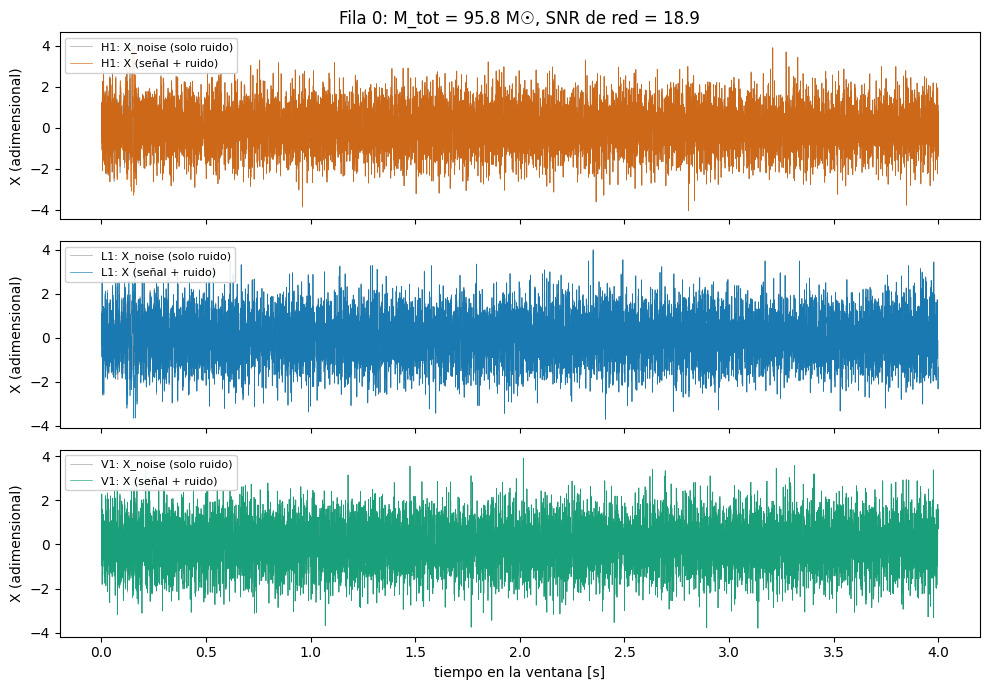

In [8]:
fs = cfg_saved['simulation']['sampling_frequency']
t = np.arange(d['X'].shape[-1]) / fs
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, (j, ifo) in zip(axes, enumerate(IFOS)):
    ax.plot(t, d['X_noise'][0, j], color='0.65', lw=0.5, label=f'{ifo}: X_noise (solo ruido)')
    ax.plot(t, d['X'][0, j], color=COLORS[ifo], lw=0.5, alpha=0.85, label=f'{ifo}: X (señal + ruido)')
    ax.set_ylabel('X (adimensional)')
    ax.legend(loc='upper left', framealpha=0.9, fontsize=8)
axes[-1].set_xlabel('tiempo en la ventana [s]')
axes[0].set_title(f"Fila {d['row_index'][0]}: M_tot = {d['total_mass'][0]:.1f} M☉, SNR de red = {d['final_network_snr'][0]:.1f}")
fig.tight_layout()
fig.savefig(OUT / 'senal_vs_ruido.png', dpi=120)
plt.show()

**Histogramas de las etiquetas** `y` = [𝓜, M_tot, χ_eff]. Con 20 señales son muy irregulares. Con un prior uniforme en m₁ y m₂, M_tot tiende a una forma triangular y χ_eff se concentra en torno a 0 (tutorial 04).

/tmp/ipykernel_318469/469029284.py:7: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/tmp/ipykernel_318469/469029284.py:8: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.savefig(OUT / 'etiquetas.png', dpi=120)
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


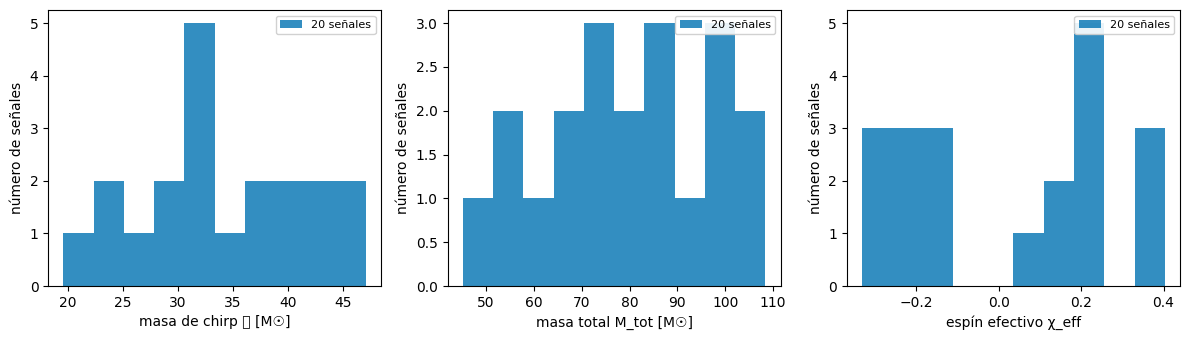

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, (k, xlabel) in zip(axes, enumerate((r'masa de chirp $\mathcal{M}$ [M☉]', 'masa total M_tot [M☉]', 'espín efectivo χ_eff'))):
    ax.hist(d['y'][:, k], bins=10, color='#0072b2', alpha=0.8, label=f'{n_ok} señales')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('número de señales')
    ax.legend(loc='upper right', framealpha=0.9, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / 'etiquetas.png', dpi=120)
plt.show()

## 9. Qué cambiar para tu estudio

Cambia el dict `config` de la sección 2, o el `config.json` de `examples/full_pipeline_example/`, y repite.

| Clave | Efecto | Ejemplo |
|---|---|---|
| `prior.masses` | Rango o forma del prior de masas | `{'distribution': 'components_uniform', 'range': [10, 80]}` · `{'distribution': 'chirp_mass_q_uniform', 'chirp_mass_range': [10, 40], 'q_range': [0.25, 1]}` |
| `prior.spin_1z`, `spin_2z` | Espines alineados | `{'distribution': 'uniform', 'range': [-1, 1]}` · `{'fixed': 0.0}` |
| `prior.target_network_snr` | Distribución de la SNR (modo `snr`) | `{'distribution': 'loguniform', 'range': [8, 30]}` · `{'fixed': 12}` |
| `mode` + `prior.distance` | Distancia física en lugar de SNR; la SNR resulta | `'mode': 'distance'` y `'distance': {'distribution': 'uniform_volume', 'range': [200, 2000]}` |
| `mode: 'noise_only'` | Solo ruido, con el mismo procesado (la distribución nula) | `'mode': 'noise_only'`, `'outputs': ['X']` |
| `outputs` | Qué arrays se guardan (192 KiB por señal cada uno) | `['X']` · `['X', 'X_noise', 'signal_whitened']` |
| `noise.splits` + `seed` | Conjuntos sin fuga de ruido | train: `['train']`, `seed` 101 · val: `['val']`, 202 · test: `['test']`, 303 |
| `n_samples` | Cuántas señales | `100000` (calcula antes el tamaño con `gwsim.estimate_size`) |
| `--workers` (CLI) | Procesos en paralelo | añade `'--workers', '4'` a `cmd` en la sección 4 |

Cuando cambies el prior, revisa los avisos de la sección 3 (`docs/VALIDEZ.md`).

## 10. Ejercicio

Repite el flujo con dos cambios:

1. **Otro prior de masas:** por ejemplo, `components_uniform` en [30, 80] M☉.
2. **Solo ruido:** `mode = 'noise_only'` y `outputs = ['X']`. En este modo no hay señal ni SNR, así que no hay `X_noise` y la prueba de la SNR no aplica.

La celda de abajo prepara la configuración. Después, vuelve a ejecutar las secciones 3 a 7 cambiando `h5_path` por `OUT / 'ejercicio.h5'`. Ten en cuenta que la sección 7 usa `X_noise` y la SNR: adapta las comprobaciones. Preguntas para pensar:

- ¿Qué metadatos quedan como NaN en `noise_only`, y por qué?
- ¿Siguen siendo la media ≈ 0 y la desviación ≈ 1? ¿Por qué tiene que ser así, haya o no señal?
- Si generas `noise_only` con la **misma** `seed` que el ejemplo, ¿sale el mismo ruido que en `X_noise`? Pista: mira qué semillas usa cada fila (`docs/CONFIGURACION.md`, «Semillas»), y si el GPS y el bloque de ruido de cada fila coinciden.

In [10]:
import copy
ejercicio = copy.deepcopy(config)
ejercicio['prior']['masses'] = {'distribution': 'components_uniform', 'range': [30.0, 80.0]}
ejercicio['mode'] = 'noise_only'
ejercicio['outputs'] = ['X']
ejercicio['description'] = 'Ejercicio: solo ruido'
ejercicio_path = OUT / 'ejercicio.json'
ejercicio_path.write_text(json.dumps(ejercicio, indent=2))
print('Escrita', ejercicio_path, '-> ahora valida, genera y comprueba (secciones 3 a 7).')

Escrita /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/00_full_pipeline_example/ejercicio.json -> ahora valida, genera y comprueba (secciones 3 a 7).
